## Gaussian Naive Bayes (GNB) — Tinh chỉnh tham số và trực quan hóa kết quả

In [1]:
from pathlib import Path
import sys
import numpy as np

# Find the project root from the notebook's working directory.
PROJECT_ROOT = Path.cwd().resolve()

# Run until found the (PROJECT_ROOT / "requirements.txt")
while not (PROJECT_ROOT / "requirements.txt").is_file():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("Cannot find the project root.")
    PROJECT_ROOT = PROJECT_ROOT.parent

# Allow imports starting with "src".
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "data" / "raw"


train_data = np.load(DATA_DIR / "mnist_train.npz")
test_data = np.load(DATA_DIR / "mnist_test.npz")

X_train, y_train = train_data["X"], train_data["y"]
X_test, y_test = test_data["X"], test_data["y"]


SEED = 42
import torch
torch.set_grad_enabled(False)

torch.autograd.grad_mode.set_grad_enabled(mode=False)

In [2]:
from src.models.naive_bayes import GaussianNaiveBayes
from src.evaluation.metrics import ClassificationMetrics
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import time
from src.preprocessing.scaler import split_val, scale_flat

In [3]:
X_train, X_val, y_train, y_val = split_val(X=X_train,y=y_train, val_size=0.1, seed=SEED)
X_train, X_val, X_test,tools = scale_flat(X_train=X_train, X_test=X_test, X_val=X_val, mode="standard")
print(f'Train: {len(X_train)}, Test: {len(X_test)}, Val: {len(X_val)}')

Global Mean: 0.1307, Global Std: 0.3082
Train: 54000, Test: 10000, Val: 6000


In [4]:
SMOOTHING_GRID = [
    1e-11, 
    1e-10,
    1e-09,
    1e-08,
    1e-07,
    1e-06,
    1e-05,  
    1e-04,  
    1e-03,  
    1e-02,  
    1e-01,  # 0.1
    0.2,
    0.5
]

SEED = 42
BATCH_SIZE = 128
DEFAULT_SMOOTHING = 1e-9

In [5]:
def run_one_model(x_train, y_train, x_val, y_val, smoothing):
    """Huấn luyện và đánh giá một giá trị var_smoothing."""
    model = GaussianNaiveBayes(smoothing, batch_size=BATCH_SIZE)

    start = time.perf_counter()
    model.fit(x_train, y_train)
    train_seconds = time.perf_counter() - start

    start = time.perf_counter()
    predictions = model.predict(x_val)
    predict_seconds = time.perf_counter() - start

    metrics = ClassificationMetrics(y_true=y_val, y_pred=predictions)
    report = metrics.evaluate()

    result = {
        "var_smoothing": smoothing,
        "accuracy": report['accuracy'],
        "macro_f1": report['macro_f1'],
        "train_seconds": train_seconds,
        "predict_seconds": predict_seconds,
    }
    return result, model, predictions

In [6]:
def tune_gnb(x_train, y_train, x_val, y_val):
    """Chạy baseline rồi tìm var_smoothing tốt nhất trên validation."""
    baseline, baseline_model, baseline_pred = run_one_model(
        x_train, y_train, x_val, y_val, DEFAULT_SMOOTHING
    )

    # khoi tao
    results = [baseline]
    best_result = baseline
    best_pred = baseline_pred
    best_model = baseline_model

    print("BASELINE (var_smoothing = 1e-9)")
    print(f"Validation accuracy: {baseline['accuracy']:.4f}")
    print(f"Validation macro F1: {baseline['macro_f1']:.4f}\n")

    print("TUNING")
    for smoothing in SMOOTHING_GRID:
        if np.isclose(smoothing, DEFAULT_SMOOTHING, rtol=1e-12, atol=0):
            continue  # Baseline đã được tính rồi.

        result, model, predictions = run_one_model(
            x_train, y_train, x_val, y_val, float(smoothing)
        )
        results.append(result)

        print(
            f"var_smoothing={smoothing:.0e} | "
            f"accuracy={result['accuracy']:.4f} | "
            f"macro_f1={result['macro_f1']:.4f}"
        )

        # Accuracy cao hơn là tiêu chí đầu, nêu acc bằng nhau thì xét đến macro_f1 cao hơns
        if (result["accuracy"], result["macro_f1"]) > (
            best_result["accuracy"], best_result["macro_f1"]
        ):
            best_result = result
            best_model = model
            best_pred = predictions

    results_df = pd.DataFrame(results).sort_values("var_smoothing")
    return (
        results_df, baseline, best_result,
        baseline_pred, best_pred, best_model
    )

In [7]:
def plot_tuning(results_df, baseline, best_result):
    """Vẽ Accuracy và Macro F1 theo var_smoothing."""
    fig, ax = plt.subplots(figsize=(9, 5))

    sns.lineplot(
        data=results_df,
        x="var_smoothing",
        y="accuracy",
        marker="o",
        label="Accuracy",
        ax=ax
    )

    sns.lineplot(
        data=results_df,
        x="var_smoothing",
        y="macro_f1",
        marker="s",
        label="Macro F1",
        ax=ax
    )

    ax.axvline(
        best_result["var_smoothing"],
        color="green",
        linestyle="--",
        label=f"Best: {best_result['var_smoothing']:.0e}"
    )

    ax.axhline(
        baseline["accuracy"],
        color="gray",
        linestyle=":",
        label="Baseline Accuracy"
    )

    ax.set_xscale("log")
    ax.set_xlabel("var_smoothing (log scale)")
    ax.set_ylabel("Validation Score")
    ax.set_title("GaussianNB: Hyperparameter Tuning")

    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()

In [8]:
def plot_confusion_matrices(y_val, baseline_pred, best_pred):
    """Vẽ Confusion Matrix trước và sau tuning (không chuẩn hóa)."""

    predictions = [baseline_pred, best_pred]
    titles = ["Baseline GNB", "Tuned GNB"]

    # Tính Confusion Matrix cho cả hai mô hình
    matrices = []
    labels_list = []

    for pred in predictions:
        cm, labels = ClassificationMetrics(
            y_true=y_val,
            y_pred=pred
        ).get_confustion_matrix()

        matrices.append(cm)
        labels_list.append(labels)

    # Sử dụng cùng thang màu cho cả hai Confusion Matrix
    max_value = max(cm.max() for cm in matrices)

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    for ax, cm, labels, title in zip(
        axes, matrices, labels_list, titles
    ):
        sns.heatmap(
            cm,
            annot=True,
            fmt=".0f",
            cmap="Blues",
            vmin=0,
            vmax=max_value,
            xticklabels=labels,
            yticklabels=labels,
            cbar=False,
            ax=ax,
            square=True
        )

        ax.set_title(title)
        ax.set_xlabel("Predicted Digit")
        ax.set_ylabel("True Digit")

    fig.suptitle(
        "GaussianNB: Confusion Matrix Comparison",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()

In [9]:
def plot_per_class_recall(y_val, baseline_pred, best_pred):
    """So sánh Recall từng chữ số trước và sau tuning."""
    labels = np.arange(10)

    baseline_recall = ClassificationMetrics(y_pred=baseline_pred, y_true=y_val).evaluate()['f1']

    best_recall = ClassificationMetrics(y_pred=best_pred, y_true=y_val).evaluate()['recall']

    plot_data = pd.DataFrame({
        "Digit": list(labels) * 2,
        "Recall": list(baseline_recall) + list(best_recall),
        "Model": ["Baseline"] * 10 + ["Tuned"] * 10
    })

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=plot_data,
        x="Digit",
        y="Recall",
        hue="Model"
    )

    plt.xlabel("Digit")
    plt.ylabel("Recall")
    plt.title("GaussianNB: Per-Class Recall Comparison")

    plt.ylim(0, 1)
    plt.legend(title="")
    plt.tight_layout()
    plt.show()

BASELINE (var_smoothing = 1e-9)
Validation accuracy: 0.5543
Validation macro F1: 0.5100

TUNING
var_smoothing=1e-11 | accuracy=0.5330 | macro_f1=0.4800
var_smoothing=1e-10 | accuracy=0.5423 | macro_f1=0.4940
var_smoothing=1e-08 | accuracy=0.5692 | macro_f1=0.5299
var_smoothing=1e-07 | accuracy=0.5845 | macro_f1=0.5492
var_smoothing=1e-06 | accuracy=0.6063 | macro_f1=0.5777
var_smoothing=1e-05 | accuracy=0.6342 | macro_f1=0.6123
var_smoothing=1e-04 | accuracy=0.6755 | macro_f1=0.6607
var_smoothing=1e-03 | accuracy=0.7285 | macro_f1=0.7213
var_smoothing=1e-02 | accuracy=0.7750 | macro_f1=0.7725
var_smoothing=1e-01 | accuracy=0.7960 | macro_f1=0.7949
var_smoothing=2e-01 | accuracy=0.7875 | macro_f1=0.7869
var_smoothing=5e-01 | accuracy=0.7590 | macro_f1=0.7594

SO SÁNH BASELINE / TUNED (VALIDATION)
Baseline accuracy: 0.5543
Tuned accuracy:    0.7960
Best smoothing:    1e-01


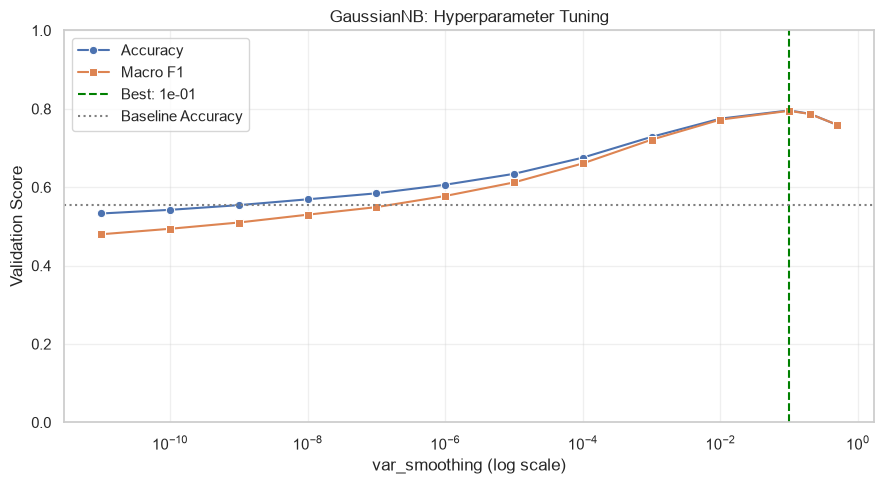

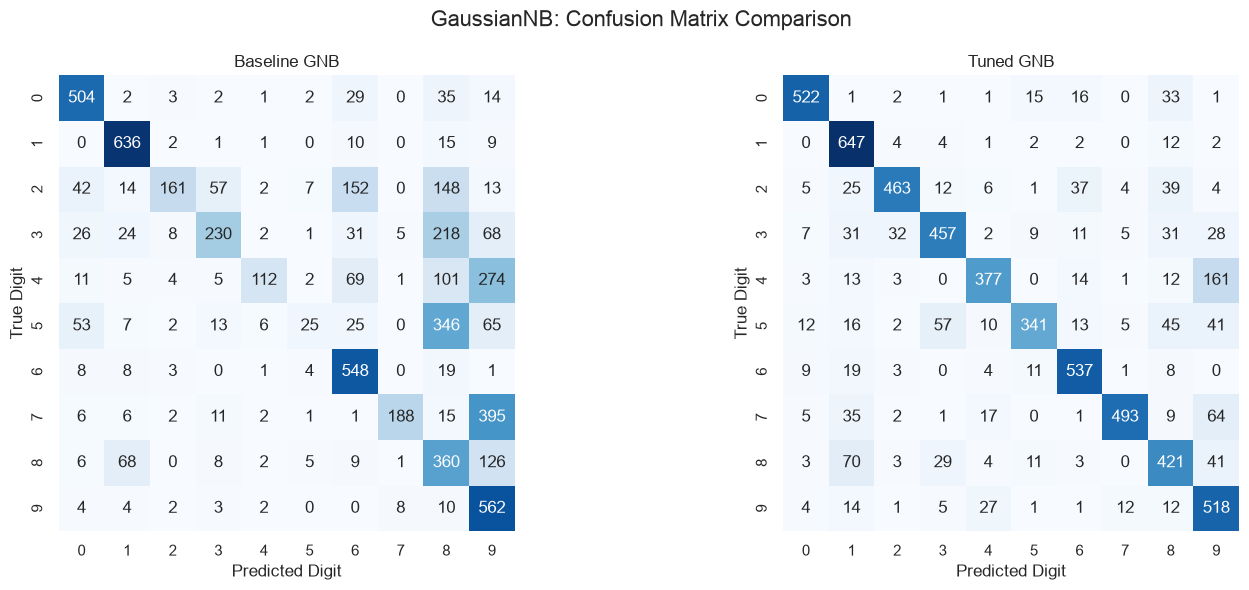

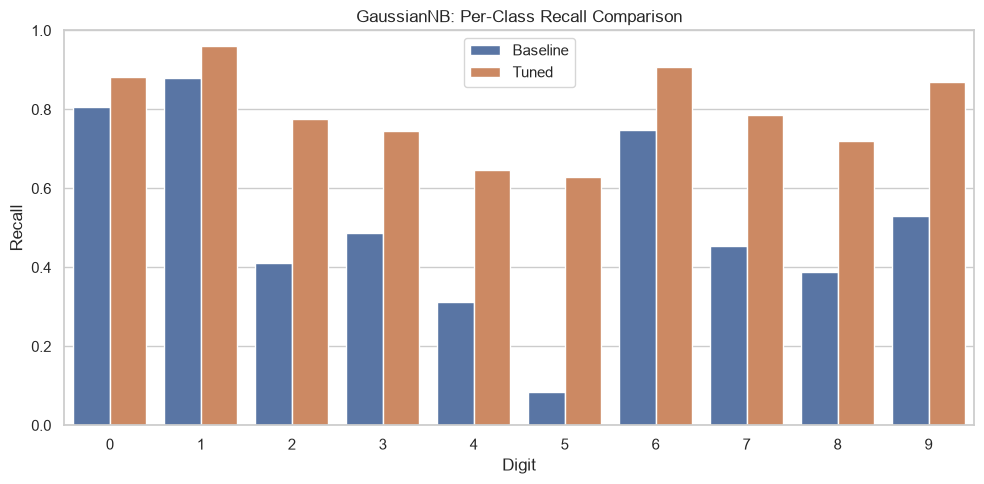

In [10]:
sns.set_theme(style="whitegrid")

(results_df, baseline, best, baseline_pred,
    best_pred, best_model) = tune_gnb(X_train, y_train, X_val, y_val)

print("\nSO SÁNH BASELINE / TUNED (VALIDATION)")
print(f"Baseline accuracy: {baseline['accuracy']:.4f}")
print(f"Tuned accuracy:    {best['accuracy']:.4f}")
print(f"Best smoothing:    {best['var_smoothing']:.0e}")

plot_tuning(results_df, baseline, best)
plot_confusion_matrices(y_val, baseline_pred, best_pred)
plot_per_class_recall(y_val, baseline_pred, best_pred)

## REPORT FINE TUNING

In [16]:
results_df

,var_smoothing,accuracy,macro_f1,train_seconds,predict_seconds
1,1.000000e-11,0.533000,0.480004,0.487682,0.292934
2,1.000000e-10,0.542333,0.493995,0.438489,0.317013
0,1.000000e-09,0.554333,0.509987,0.505448,0.262456
3,1.000000e-08,0.569167,0.529934,0.442495,0.263803
4,1.000000e-07,0.584500,0.549236,0.421707,0.268607
5,1.000000e-06,0.606333,0.577652,0.437107,0.272818
6,1.000000e-05,0.634167,0.612268,0.495045,0.384283
7,1.000000e-04,0.675500,0.660747,0.686003,0.303188
8,1.000000e-03,0.728500,0.721276,0.420309,0.264671
9,1.000000e-02,0.775000,0.772511,0.415044,0.259494


## BASE MODEL

In [20]:
results_df.iloc[0]

var_smoothing      1.000000e-11
accuracy           5.330000e-01
macro_f1           4.800043e-01
train_seconds      4.876824e-01
predict_seconds    2.929339e-01
Name: 1, dtype: float64

## BEST MODEL 

In [18]:
results_df.iloc[10]

var_smoothing      0.100000
accuracy           0.796000
macro_f1           0.794941
train_seconds      0.415839
predict_seconds    0.263712
Name: 10, dtype: float64

## SỬ DỤNG BEST MODEL TRÊN TẬP TEST HOÀN TONÀ CHƯA ĐƯỢC NHÌN THẤY

In [19]:
# Chỉ đánh giá test sau khi đã chọn tham số bằng validation.
test_pred = best_model.predict(X_test)
print("\nKẾT QUẢ TEST CỦA MÔ HÌNH TỐT NHẤT")

report = ClassificationMetrics(y_true=y_test,y_pred=test_pred).evaluate()

print(f"Test accuracy: {report['accuracy']:.4f}")
print(f"Test macro F1: {report['macro_f1']:.4f}")


KẾT QUẢ TEST CỦA MÔ HÌNH TỐT NHẤT
Test accuracy: 0.8149
Test macro F1: 0.8133


## LƯU TRỌNG SỐ MÔ HÌNH

In [22]:
import joblib

# Thiết lập đường dẫn thư mục models
MODELS_DIR = PROJECT_ROOT / 'models'
MODELS_DIR.mkdir(parents=True, exist_ok=True)  # Tự động tạo thư mục nếu chưa tồn tại

print(f"Đang lưu mô hình vào thư mục: {MODELS_DIR.absolute()}")


if 'best_model' in locals():
    nb_path = MODELS_DIR / "naive_bayes.joblib"
    joblib.dump(best_model, nb_path)
    print(f"Đã lưu Naive Bayes tại: {nb_path}")

Đang lưu mô hình vào thư mục: /home/nguyenhaianh/Desktop/Classify_Number/models
Đã lưu Naive Bayes tại: /home/nguyenhaianh/Desktop/Classify_Number/models/naive_bayes.joblib
